# Agora é com vocês, tentem enganar a rede

A rede foi treinada só com pedidos bem avaliados da Olist. Pra cada pedido, ela tenta reconstruir os 10 números
e mede o quanto errou. Se o erro passar do limite **τ**, o pedido vira **alerta**.

In [ ]:
import warnings
import joblib
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

warnings.filterwarnings("ignore")

salvo = joblib.load("modelo_olist.joblib")
modelo = salvo["modelo"]
escala = salvo["escala"]
tau = salvo["tau"]
colunas = salvo["colunas"]

NOMES = ["prazo prometido", "prazo real", "diferença de prazo", "preço", "frete",
         "frete / preço", "peso", "volume", "distância", "parcelas"]


def avaliar(pedido):
    # monta os 10 números do pedido, do mesmo jeito que no treino
    linha = {
        "prazo_prometido": pedido["prazo_prometido"],
        "prazo_real": pedido["prazo_real"],
        "diferenca": pedido["prazo_real"] - pedido["prazo_prometido"],
        "preco": np.log1p(pedido["preco"]),
        "frete": np.log1p(pedido["frete"]),
        "frete_preco": pedido["frete"] / pedido["preco"],
        "peso": np.log1p(pedido["peso"]),
        "volume": np.log1p(pedido["volume"]),
        "distancia": np.log1p(pedido["distancia"]),
        "parcelas": pedido["parcelas"],
    }
    entrada = pd.DataFrame([linha], columns=colunas)

    x = escala.transform(entrada)
    reconstruido = modelo.predict(x)
    erro_por_numero = (x[0] - reconstruido[0]) ** 2
    erro = erro_por_numero.mean()

    # result em texto
    print("Erro de reconstrução:", round(erro, 2), "   limite τ:", round(tau, 2))
    if erro > tau:
        print("ALERTA: a rede achou esse pedido estranho")
    else:
        print("Normal: a rede conseguiu reconstruir esse pedido")
    ordem = np.argsort(erro_por_numero)[::-1]
    print("O que mais fugiu do padrão:", NOMES[ordem[0]] + ",", NOMES[ordem[1]] + " e", NOMES[ordem[2]])

    # plot do grafico de visualização de quanto cada feature contribuiu
    cor = "tab:orange" if erro > tau else "tab:blue"
    plt.figure(figsize=(8, 4))
    plt.barh(NOMES, erro_por_numero / len(NOMES), color=cor)
    plt.gca().invert_yaxis()
    plt.xlabel("parte do erro que veio de cada número")
    if erro > tau:
        plt.title("ALERTA  (erro " + str(round(erro, 2)) + " > τ " + str(round(tau, 2)) + ")")
    else:
        plt.title("Normal  (erro " + str(round(erro, 2)) + " ≤ τ " + str(round(tau, 2)) + ")")
    plt.tight_layout()
    plt.show()


print("Rede carregada. Limite τ =", round(tau, 2))

Rede carregada. Limite τ = 2.48


## Um pedido comum da base (pra mostrar como fica um pedido normal)

Erro de reconstrução: 0.28    limite τ: 2.48
Normal: a rede conseguiu reconstruir esse pedido
O que mais fugiu do padrão: parcelas, volume e diferença de prazo


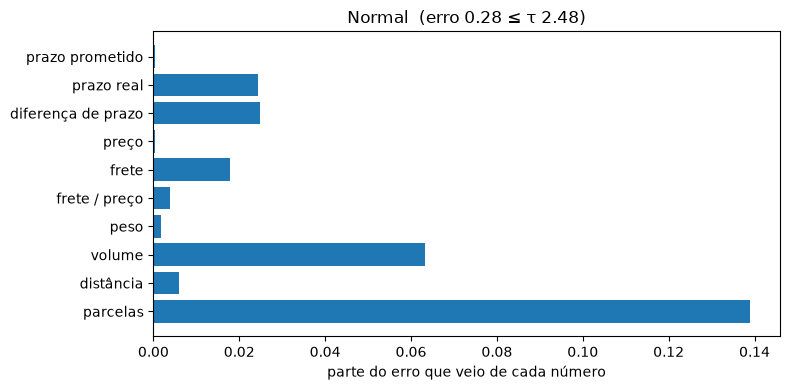

In [2]:
pedido = {
    "prazo_prometido": 20,   # dias
    "prazo_real": 13,        # dias
    "preco": 88.95,          # R$
    "frete": 12.96,          # R$
    "peso": 950,             # gramas
    "volume": 2560,          # cm³
    "distancia": 296,        # km entre cliente e vendedor
    "parcelas": 6,
}
avaliar(pedido)

## Vez da turma (Por favor, se voluntariem !!)

Erro de reconstrução: 0.28    limite τ: 2.48
Normal: a rede conseguiu reconstruir esse pedido
O que mais fugiu do padrão: parcelas, volume e diferença de prazo


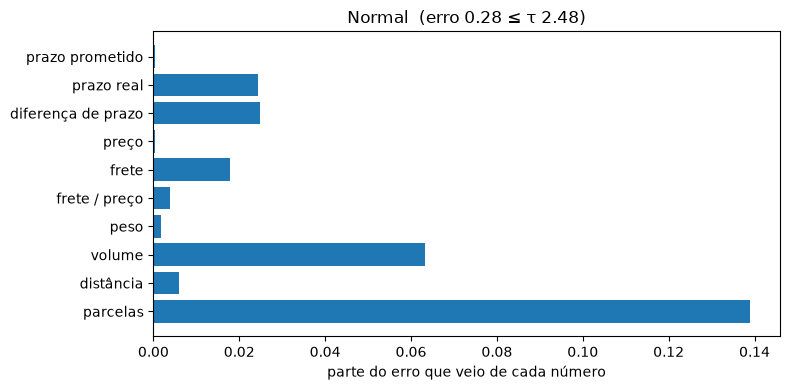

In [3]:
pedido_da_turma = {
    "prazo_prometido": 20,   # dias
    "prazo_real": 13,        # dias
    "preco": 88.95,          # R$
    "frete": 12.96,          # R$
    "peso": 950,             # gramas
    "volume": 2560,          # cm³
    "distancia": 296,        # km entre cliente e vendedor
    "parcelas": 6,
}
avaliar(pedido_da_turma)

## Exemplos prontos, se ninguém se dispor (espero que não)

Erro de reconstrução: 259.52    limite τ: 2.48
ALERTA: a rede achou esse pedido estranho
O que mais fugiu do padrão: frete / preço, preço e volume


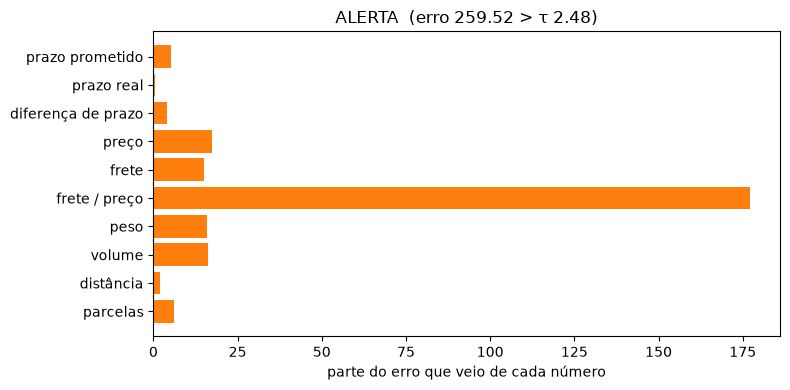

In [7]:
frete_caro = {"prazo_prometido": 20, "prazo_real": 10, "preco": 0.85, "frete": 18.23,
              "peso": 300, "volume": 1000, "distancia": 490, "parcelas": 1}
avaliar(frete_caro)

Erro de reconstrução: 21.56    limite τ: 2.48
ALERTA: a rede achou esse pedido estranho
O que mais fugiu do padrão: prazo real, diferença de prazo e volume


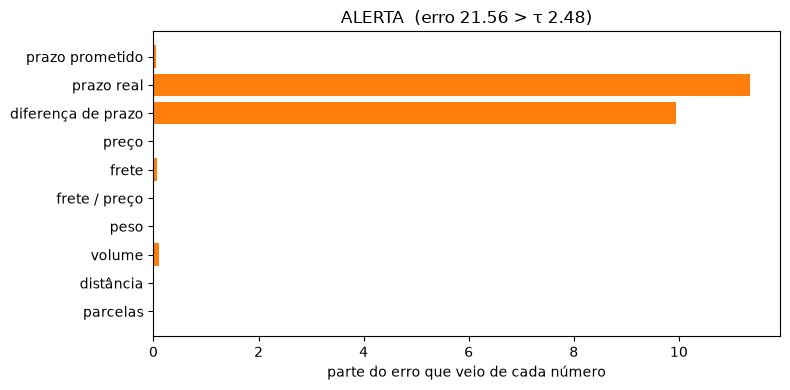

In [ ]:
atrasou_muito = {"prazo_prometido": 20, "prazo_real": 90, "preco": 120, "frete": 15, 
                 "peso": 800, "volume": 3000, "distancia": 400, "parcelas": 3}
avaliar(atrasou_muito)

Erro de reconstrução: 2.57    limite τ: 2.48
ALERTA: a rede achou esse pedido estranho
O que mais fugiu do padrão: frete, diferença de prazo e preço


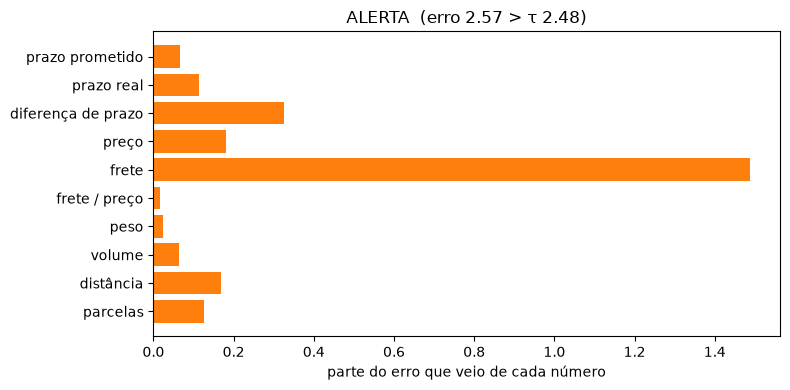

In [ ]:
# exemplo de uma geladeira de 70 kg, entregue em 3 dias, com frete de R$ 5
geladeira_barata = {"prazo_prometido": 25, "prazo_real": 3, "preco": 2500, "frete": 5,
                    "peso": 70000, "volume": 500000, "distancia": 1200, "parcelas": 10}
avaliar(geladeira_barata)